## What Actually Wins Games in MLB? Predicting Team Wins from Stats
### Author: Ryan Corbin

This notebook analyzes team-level Major League Baseball (MLB) statistics from the Lahman Baseball Database to model and predict regular-season team wins from season-level performance metrics. We focus on modern seasons and compare how offensive, pitching, and defensive statistics relate to success.

### Project goals
- Build supervised learning models to predict team wins from batting, pitching, and defensive statistics.
- Identify which metrics are most strongly associated with higher win totals.
- Explore whether the drivers of team success change over recent MLB seasons.

This workflow mirrors the structure of the prior DSCI 470 project but with a focused predictive modeling goal.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)

### Data loading

This analysis uses the Lahman Baseball Database (Teams table or a pre-joined team-season file).
Update the `data_path` variable below to point to your local CSV extracted from Lahman (e.g., `mlb_teams.csv` joined with batting, pitching, and fielding summaries if needed).


In [5]:
data_path = "./data/mlb_teams.csv"

teams = pd.read_csv(data_path)
print(teams.columns.tolist())
teams.head()

#Rename key columns to shorter names
teams = teams.rename(columns={
    "year": "yearID",
    "league_id": "lgID",
    "division_id": "divID",
    "games_played": "G",
    "wins": "W",
    "losses": "L",
    "runs_scored": "R",
    "opponents_runs_scored": "RA"
})

#Derived metrics
teams["WinPct"] = teams["W"] / teams["G"]
teams["RunDiff"] = teams["R"] - teams["RA"]
teams["R_per_game"] = teams["R"] / teams["G"]
teams["RA_per_game"] = teams["RA"] / teams["G"]

#show columns and first few rows
print(teams.columns.tolist())
teams.tail()

['year', 'league_id', 'division_id', 'rank', 'games_played', 'home_games', 'wins', 'losses', 'division_winner', 'wild_card_winner', 'league_winner', 'world_series_winner', 'runs_scored', 'at_bats', 'hits', 'doubles', 'triples', 'homeruns', 'walks', 'strikeouts_by_batters', 'stolen_bases', 'caught_stealing', 'batters_hit_by_pitch', 'sacrifice_flies', 'opponents_runs_scored', 'earned_runs_allowed', 'earned_run_average', 'complete_games', 'shutouts', 'saves', 'outs_pitches', 'hits_allowed', 'homeruns_allowed', 'walks_allowed', 'strikeouts_by_pitchers', 'errors', 'double_plays', 'fielding_percentage', 'team_name', 'ball_park', 'home_attendance']
['yearID', 'lgID', 'divID', 'rank', 'G', 'home_games', 'W', 'L', 'division_winner', 'wild_card_winner', 'league_winner', 'world_series_winner', 'R', 'at_bats', 'hits', 'doubles', 'triples', 'homeruns', 'walks', 'strikeouts_by_batters', 'stolen_bases', 'caught_stealing', 'batters_hit_by_pitch', 'sacrifice_flies', 'RA', 'earned_runs_allowed', 'earned

,yearID,lgID,divID,rank,G,home_games,W,L,division_winner,wild_card_winner,league_winner,world_series_winner,R,at_bats,hits,doubles,triples,homeruns,walks,strikeouts_by_batters,stolen_bases,caught_stealing,batters_hit_by_pitch,sacrifice_flies,RA,earned_runs_allowed,earned_run_average,complete_games,shutouts,saves,outs_pitches,hits_allowed,homeruns_allowed,walks_allowed,strikeouts_by_pitchers,errors,double_plays,fielding_percentage,team_name,ball_park,home_attendance,WinPct,RunDiff,R_per_game,RA_per_game
2929,2025,NL,C,4,162,81.0,78,84,N,N,N,N,689,5433,1331,264,9,148,478,1321.0,89.0,27.0,88.0,40.0,754,684,4.30,2,13,42,4296,1434,170,461,1209,80,124,0.987,St. Louis Cardinals,Busch Stadium III,2250007.0,0.481481,-65,4.253086,4.654321
2930,2025,AL,E,4,162,81.0,77,85,N,N,N,N,714,5470,1374,242,16,182,468,1397.0,194.0,48.0,46.0,43.0,683,627,3.94,1,11,35,4294,1273,205,474,1416,81,147,0.986,Tampa Bay Rays,Steinbrenner Field,786750.0,0.475309,31,4.407407,4.216049
2931,2025,AL,W,3,162,81.0,81,81,N,N,N,N,684,5443,1275,245,15,175,486,1327.0,134.0,33.0,63.0,40.0,605,560,3.49,2,14,37,4329,1235,172,463,1344,51,122,0.991,Texas Rangers,Globe Life Field,2397071.0,0.500000,79,4.222222,3.734568
2932,2025,AL,E,1,162,81.0,94,68,Y,N,Y,N,798,5507,1461,294,13,191,520,1099.0,77.0,25.0,65.0,45.0,721,669,4.19,2,8,42,4314,1313,209,517,1430,86,118,0.985,Toronto Blue Jays,Rogers Centre,2849935.0,0.580247,77,4.925926,4.450617
2933,2025,NL,E,5,162,81.0,66,96,N,N,N,N,687,5422,1313,258,28,161,443,1351.0,132.0,48.0,57.0,40.0,899,846,5.35,0,9,37,4270,1491,214,566,1248,94,131,0.984,Washington Nationals,Nationals Park,1916768.0,0.407407,-212,4.240741,5.549383


### Filter to modern era and basic cleaning

We restrict attention to a recent era to keep rules and style of play reasonably consistent (for example, 1998 onward, after league expansion and division realignment). We also create derived rate statistics and a target variable for wins.

In [7]:
# Choose a modern window; adjust as desired
year_min, year_max = 1998, 2025

modern = teams.query("yearID >= @year_min and yearID <= @year_max").copy()

# Basic derived stats (adjust column names if your file differs)
# Example Lahman-like columns: G, W, L, R, RA, at_bats, hits, doubles, triples, homeruns, walks,
# earned_run_average, errors, double_plays, fielding_percentage

if "G" in modern.columns:
    modern["WinPct"] = modern["W"] / modern["G"]

# Per-game rates
for col in ["R", "RA", "hits", "homeruns", "walks", "errors"]:
    if col in modern.columns and "G" in modern.columns:
        modern[f"{col}_per_game"] = modern[col] / modern["G"]

# Run differential
if set(["R", "RA"]).issubset(modern.columns):
    modern["RunDiff"] = modern["R"] - modern["RA"]

modern[["yearID", "teamID" if "teamID" in modern.columns else modern.columns[0], "W", "WinPct"]].tail()

,yearID,yearID,W,WinPct
2929,2025,2025,78,0.481481
2930,2025,2025,77,0.475309
2931,2025,2025,81,0.500000
2932,2025,2025,94,0.580247
2933,2025,2025,66,0.407407


### Exploratory data analysis

We first examine distributions and pairwise relationships among wins and key team stats to understand broad patterns and multicollinearity.

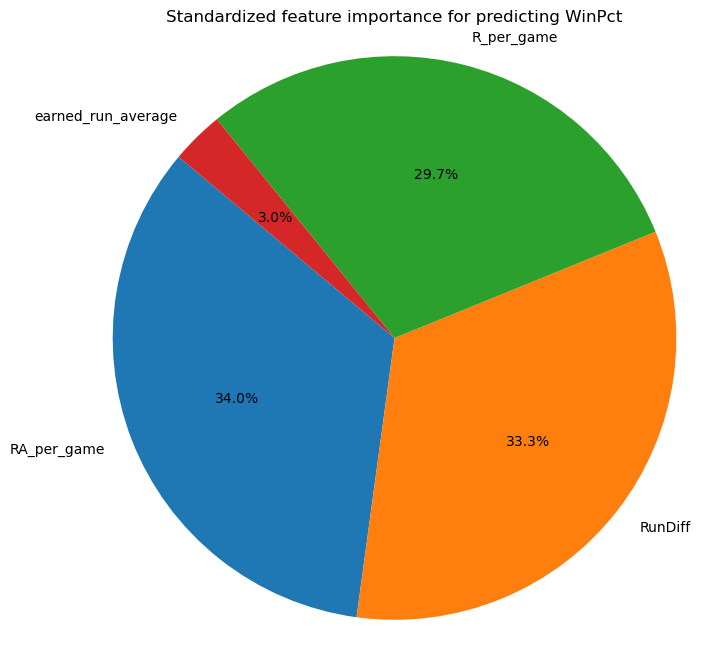

,Feature,Std_Coefficient,Importance,ImportancePct
2,RA_per_game,-0.041453,0.041453,33.958672
0,RunDiff,0.040659,0.040659,33.308856
1,R_per_game,0.036258,0.036258,29.703194
3,earned_run_average,0.003698,0.003698,3.029279


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt

# Use the same predictors from Q3
features = [
    "RunDiff",
    "R_per_game",
    "RA_per_game",
    "earned_run_average"
]

# Keep only complete rows
model_df = teams.dropna(subset=features + ["WinPct"]).copy()

X = model_df[features]
y = model_df["WinPct"]

# Standardize predictors
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit regression on standardized predictors
linreg_std = LinearRegression()
linreg_std.fit(X_scaled, y)

# Build coefficient table
coef_df = pd.DataFrame({
    "Feature": features,
    "Std_Coefficient": linreg_std.coef_
})

# Importance based on absolute standardized coefficient
coef_df["Importance"] = coef_df["Std_Coefficient"].abs()
coef_df["ImportancePct"] = 100 * coef_df["Importance"] / coef_df["Importance"].sum()

# Sort largest to smallest
coef_df = coef_df.sort_values("ImportancePct", ascending=False)

# Pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    coef_df["ImportancePct"],
    labels=coef_df["Feature"],
    autopct="%1.1f%%",
    startangle=140
)
plt.title("Standardized feature importance for predicting WinPct")
plt.axis("equal")
plt.show()

coef_df

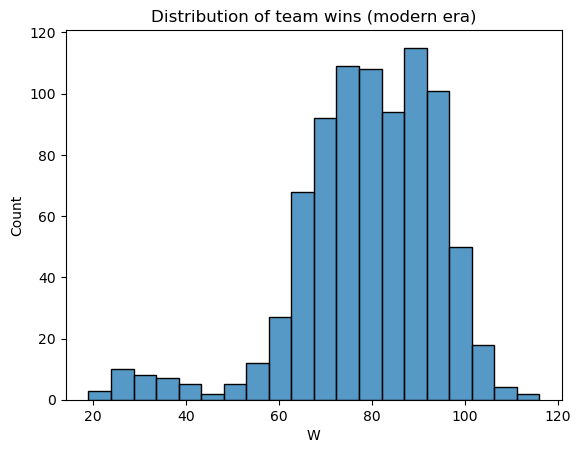

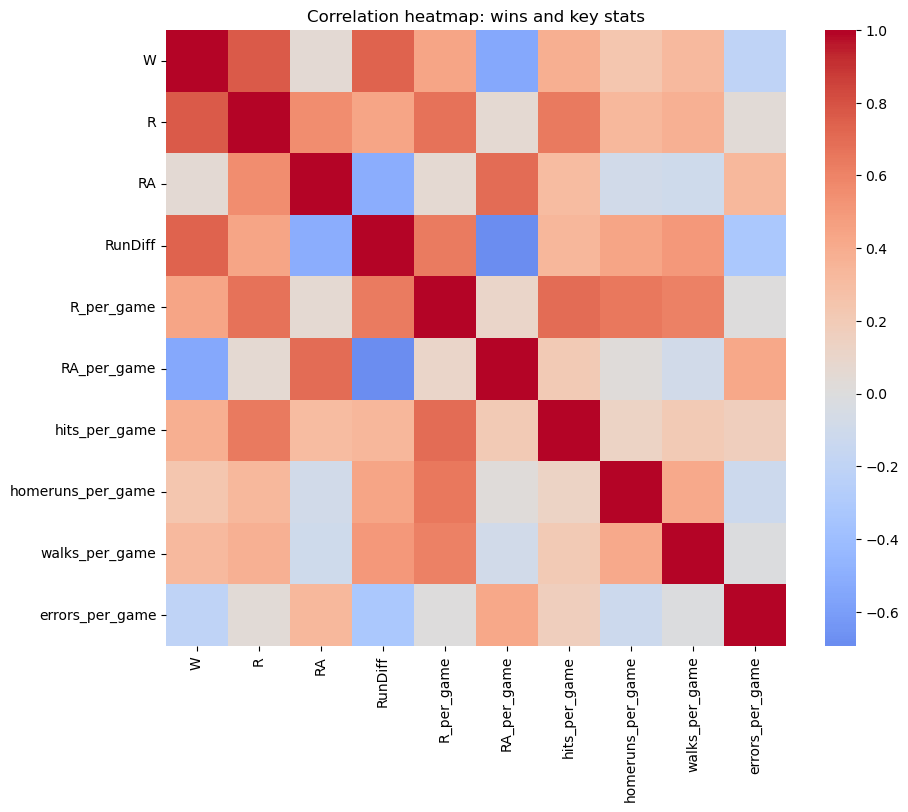

In [10]:
numeric_cols = [c for c in modern.columns if modern[c].dtype != "O"]

sns.histplot(modern["W"], bins=20)
plt.title("Distribution of team wins (modern era)")
plt.show()

corr = modern[["W", "R", "RA", "RunDiff"] + [c for c in modern.columns if "_per_game" in c if c in modern.columns]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation heatmap: wins and key stats")
plt.show()

### Modeling setup

We model total wins `W` as a function of pre- or full-season team statistics. Here we start by using full-season features to understand which metrics are most strongly associated with wins, then we can later restrict to early-season splits if available.

In [12]:
# Choose features; adjust based on your available columns
candidate_features = [
    "R", "RA", "RunDiff",
    "R_per_game", "RA_per_game" if "RA_per_game" in modern.columns else None,
    "hits_per_game" if "hits_per_game" in modern.columns else None,
    "homeruns_per_game" if "homeruns_per_game" in modern.columns else None,
    "walks_per_game" if "walks_per_game" in modern.columns else None,
    "errors_per_game" if "errors_per_game" in modern.columns else None,
    "earned_run_average" if "earned_run_average" in modern.columns else None,
]

feature_cols = [c for c in candidate_features if c is not None and c in modern.columns]

print("Using features:", feature_cols)

X = modern[feature_cols].copy()
y = modern["W"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=470
)

Using features: ['R', 'RA', 'RunDiff', 'R_per_game', 'RA_per_game', 'hits_per_game', 'homeruns_per_game', 'walks_per_game', 'errors_per_game', 'earned_run_average']


### Linear regression model

We begin with an ordinary least squares linear regression to capture linear relationships between team stats and wins and to obtain interpretable coefficients.

In [14]:
lin_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

lin_pipeline.fit(X_train, y_train)

y_pred = lin_pipeline.predict(X_test)

rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

print(f"Linear regression RMSE: {rmse:.2f}")
print(f"Linear regression R^2: {r2:.3f}")

# Coefficients in original feature space
coef = lin_pipeline.named_steps["model"].coef_
coef_df = pd.DataFrame({"feature": feature_cols, "coefficient": coef}).sort_values("coefficient", ascending=False)
coef_df

Linear regression RMSE: 4.39
Linear regression R^2: 0.921


,feature,coefficient
0,R,10.334567
2,RunDiff,8.481675
1,RA,1.798650
5,hits_per_game,0.674302
6,homeruns_per_game,0.601172
4,RA_per_game,0.047373
7,walks_per_game,-0.038308
8,errors_per_game,-0.408448
9,earned_run_average,-3.668993
3,R_per_game,-6.281791


### Regularized linear models (Ridge, Lasso)

To handle multicollinearity among team statistics and potentially improve generalization, we fit ridge and lasso regression models and compare their performance.

In [16]:
alphas = [0.01, 0.1, 1.0, 10.0]

ridge_results = []
lasso_results = []

for a in alphas:
    ridge = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=a))
    ])
    ridge.fit(X_train, y_train)
    y_pred_r = ridge.predict(X_test)
    ridge_results.append({
        "alpha": a,
        "rmse": mean_squared_error(y_test, y_pred_r, squared=False),
        "r2": r2_score(y_test, y_pred_r)
    })

    lasso = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=a))
    ])
    lasso.fit(X_train, y_train)
    y_pred_l = lasso.predict(X_test)
    lasso_results.append({
        "alpha": a,
        "rmse": mean_squared_error(y_test, y_pred_l, squared=False),
        "r2": r2_score(y_test, y_pred_l)
    })

ridge_df = pd.DataFrame(ridge_results)
lasso_df = pd.DataFrame(lasso_results)

print("Ridge results:")
print(ridge_df)

print("Lasso results:")
print(lasso_df)

Ridge results:
   alpha      rmse        r2
0   0.01  4.385971  0.921113
1   0.10  4.387480  0.921058
2   1.00  4.405149  0.920421
3  10.00  4.566327  0.914492
Lasso results:
   alpha       rmse        r2
0   0.01   4.398754  0.920652
1   0.10   4.690585  0.909775
2   1.00   5.099624  0.893352
3  10.00  14.059330  0.189404


### Tree-based model: Random forest

To capture nonlinear relationships and interactions among statistics, we fit a random forest regressor and examine feature importances.

Random forest RMSE: 4.52
Random forest R^2: 0.916


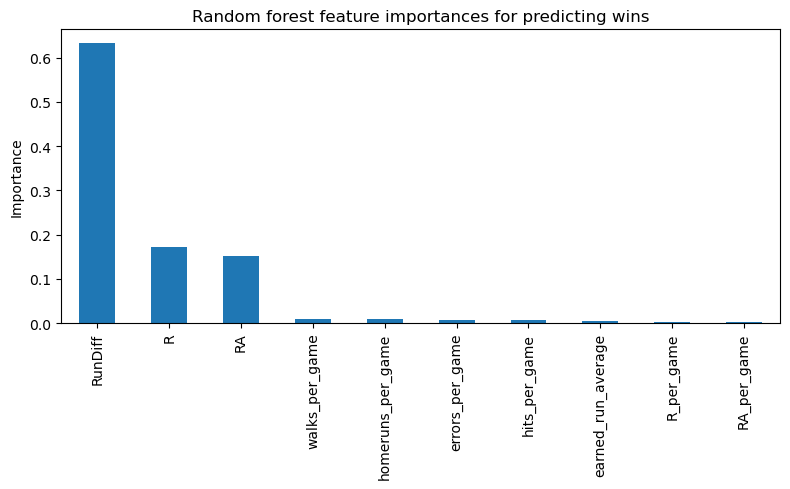

RunDiff               0.632122
R                     0.171566
RA                    0.152058
walks_per_game        0.009675
homeruns_per_game     0.009310
errors_per_game       0.007628
hits_per_game         0.006949
earned_run_average    0.004935
R_per_game            0.003293
RA_per_game           0.002465
dtype: float64

In [18]:
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=470,
    min_samples_leaf=2,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rmse_rf = mean_squared_error(y_test, y_pred_rf, squared=False)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random forest RMSE: {rmse_rf:.2f}")
print(f"Random forest R^2: {r2_rf:.3f}")

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importances.plot(kind="bar")
plt.ylabel("Importance")
plt.title("Random forest feature importances for predicting wins")
plt.tight_layout()
plt.show()

importances

### Do drivers change over time?

To explore whether the importance of different statistics shifts across eras, we can fit separate models for early vs. late subsets of the modern era and compare feature importance patterns.

In [20]:
# Example split: 1998–2009 vs. 2010–2025
modern["era"] = np.where(modern["yearID"] <= 2009, "1998-2009", "2010-2025")

era_importances = {}

for era, df_era in modern.groupby("era"):
    X_era = df_era[feature_cols]
    y_era = df_era["W"]

    rf_era = RandomForestRegressor(n_estimators=500, random_state=470, min_samples_leaf=2, n_jobs=-1)
    rf_era.fit(X_era, y_era)
    era_importances[era] = pd.Series(rf_era.feature_importances_, index=feature_cols).sort_values(ascending=False)

era_importances

{'1998-2009': RunDiff               0.915636
 homeruns_per_game     0.015388
 walks_per_game        0.014583
 errors_per_game       0.013605
 hits_per_game         0.011465
 earned_run_average    0.008009
 R_per_game            0.006391
 R                     0.006212
 RA_per_game           0.004478
 RA                    0.004234
 dtype: float64,
 '2010-2025': R                     0.444938
 RunDiff               0.431452
 RA                    0.087773
 walks_per_game        0.007713
 homeruns_per_game     0.006493
 errors_per_game       0.006308
 hits_per_game         0.005856
 earned_run_average    0.004887
 R_per_game            0.002347
 RA_per_game           0.002232
 dtype: float64}

### Predicting Each Team's Win Totals in the Upcoming Season

Use the data that has been collected and narrow it down the most important stats needed to predict the number of wins in the following season for each team. I have copied Question 3 from the DSCI 470 final project to assist with comparing the information that has been presented.

In [22]:
# Question 3 (copied over from DSCI 470 project)
# To what extent can simple team-level features (such as run differential and runs per game)
# predict team winning percentage, and how can we turn that into predicted wins?

# 1. Choose numeric predictors (must match your earlier feature engineering)
features = [
    "RunDiff",
    "R_per_game",
    "RA_per_game",
    "earned_run_average"
]

# Drop rows with missing predictors or WinPct
model_df = teams.dropna(subset=features + ["WinPct", "G"]).copy()

X = model_df[features]
y = model_df["WinPct"]

# 2. Train/test split and fit linear regression on WinPct (Q3 core)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linreg = LinearRegression()
linreg.fit(X_train, y_train)

y_pred = linreg.predict(X_test)

r2 = r2_score(y_test, y_pred)       # relationship between stats and WinPct
mae = mean_absolute_error(y_test, y_pred)  # average absolute difference
print("Test R^2:", r2)
print("Test MAE (WinPct):", mae)

# 3. Use the model to predict WinPct and wins for historical team-seasons
model_df["PredWinPct"] = linreg.predict(model_df[features])
model_df["PredWins"] = model_df["PredWinPct"] * model_df["G"]
model_df["PredWins_round"] = model_df["PredWins"].round().astype(int)

# Peek at a few rows: actual vs predicted wins
print(
    model_df[["yearID", "team_name", "G", "W", "WinPct",
              "PredWinPct", "PredWins_round"]]
    .tail(10)
)

Test R^2: 0.9004117744086996
Test MAE (WinPct): 0.02160348806489091
      yearID              team_name    G   W    WinPct  PredWinPct  \
2924    2025  Philadelphia Phillies  162  96  0.592593    0.580530   
2925    2025     Pittsburgh Pirates  162  71  0.438272    0.461858   
2926    2025       San Diego Padres  162  90  0.555556    0.550568   
2927    2025       Seattle Mariners  162  90  0.555556    0.543391   
2928    2025   San Francisco Giants  162  81  0.500000    0.512103   
2929    2025    St. Louis Cardinals  162  78  0.481481    0.458436   
2930    2025         Tampa Bay Rays  162  77  0.475309    0.518747   
2931    2025          Texas Rangers  162  81  0.500000    0.549259   
2932    2025      Toronto Blue Jays  162  94  0.580247    0.546893   
2933    2025   Washington Nationals  162  66  0.407407    0.366934   

      PredWins_round  
2924              94  
2925              75  
2926              89  
2927              88  
2928              83  
2929              74  


In [23]:
last_year = teams["yearID"].max()
window_start = last_year - 4

recent = teams.loc[teams["yearID"].between(window_start, last_year)].copy()
recent = recent.dropna(subset=features + ["G"])

# Per-team averages over the last 10 seasons
team_avgs = (
    recent
    .groupby("team_name", as_index=False)
    .agg({
        "RunDiff":            "mean",
        "R_per_game":         "mean",
        "RA_per_game":        "mean",
        "earned_run_average": "mean",
        "G":                  "mean"
    })
)

team_avgs["PredWinPct"] = linreg.predict(team_avgs[features])
team_avgs["PredWins"] = team_avgs["PredWinPct"] * team_avgs["G"]
team_avgs["PredWins_round"] = team_avgs["PredWins"].round().astype(int)

# --- NEW PART: attach last-season wins for comparison ---

# Get each team's wins in the most recent season
last_season = (
    teams[teams["yearID"] == last_year]
    .loc[:, ["team_name", "W", "WinPct"]]
    .rename(columns={"W": "LastSeason_W", "WinPct": "LastSeason_WinPct"})
)

# Merge onto the predictions
comparison = (
    team_avgs
    .merge(last_season, on="team_name", how="left")
    .sort_values("PredWins", ascending=False)
)

# Select and display key columns
comparison[[
    "team_name",
    "LastSeason_W",
    "LastSeason_WinPct",
    "PredWins_round",
    "PredWinPct"
]]

,team_name,LastSeason_W,LastSeason_WinPct,PredWins_round,PredWinPct
13,Los Angeles Dodgers,93,0.574074,103,0.636796
10,Houston Astros,87,0.537037,94,0.582140
1,Atlanta Braves,76,0.469136,94,0.578065
18,New York Yankees,94,0.580247,92,0.569829
15,Milwaukee Brewers,97,0.598765,92,0.566533
26,Tampa Bay Rays,77,0.475309,89,0.552216
20,Philadelphia Phillies,96,0.592593,88,0.545881
28,Toronto Blue Jays,94,0.580247,88,0.543811
22,San Diego Padres,90,0.555556,88,0.542156
24,Seattle Mariners,90,0.555556,86,0.531220
